# Hwang et al. 2022 — Pancreatic Ductal Adenocarcinoma (snRNA-seq, 10x, TP10K)
## 01 · Preprocessing & Gate 1

Load malignant nuclei from the three group matrices, threshold under-populated samples,
select overdispersed genes, PCA, Harmony-integrate on `sample` (integration strength swept),
embed, remove detached islands, resolve the density lobes and check each for a proliferation
confound, and settle **Gate 1** (mixing + continuity) on the regenerated embedding — not on a
scalar alone (03_eval fork 1).

Notebook lives two levels below the Puram reference (`<Category>/<Dataset>/`); paths are adapted
so it runs in place.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, anndata as ad
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# --- adapted relative paths: notebook is <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset> ---
name = os.path.basename(os.getcwd())                 # Hwang2022_Pancreas-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))# Pancreas
pth  = os.path.join(*([os.pardir]*6))                # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Hwang2022_Pancreas')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
print('input :', pth_in)
print('h5ads :', pth_out)
print('figs  :', pth_fig)

input : ../../../../../../data/unzip/CCCA/Data_Hwang2022_Pancreas
h5ads : ../../../../../../data/cancer/vertebrate/CCCA/Claude/Pancreas/Hwang2022_Pancreas-3
figs  : ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Pancreas/Hwang2022_Pancreas-3


**Load & select malignant nuclei.** Hwang 2022 ships three group matrices (TP10K-normalized
snRNA-seq); the loader is pointed at each leaf matrix directory exactly as `merge.py` walks them,
and the malignant nuclei are concatenated. TP10K passes through the loader unchanged (already
normalized), then `log1p`.

In [ ]:
leaves = sorted(dp for dp, sub, fs in os.walk(pth_in)
                if any(f.endswith('.mtx') for f in fs))
parts = {}
for l in leaves:
    a = load_CCCA_adata(l, verbose=False)
    parts[os.path.basename(l)] = a
adata = ad.concat(parts, join='outer', merge='same', label='group')
adata.obs_names_make_unique()
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant nuclei (raw):', adata.n_obs, 'across', adata.obs['sample'].nunique(), 'samples')

malignant nuclei (raw): 64538 across 43 samples


**Sample threshold.** The reference derives a min-cell threshold from an inflection in the
per-sample counts. Here the distribution declines smoothly from ~7,200 to ~100, then drops into a
tail of non-viable specks (85 → 3 nuclei). The largest multiplicative gap sits **inside that
speck tail** (24 → 9), so the gap heuristic is degenerate (02_train C3: the "clean count gap"
assumption fails on a smooth distribution). I fall back to the reference's **≥100-cell floor**
(the well-precedented default — Puram, Steele PDAC), which cleanly separates the 29 populated
tumours from the specks.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('per-sample malignant counts (sorted desc):'); print(n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap} of {len(vals)} -> in the speck tail, degenerate')
FLOOR = 100
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'threshold = >={FLOOR} cells (floor); kept {len(keep)}/{n.size} samples, '
      f'{adata.n_obs} nuclei; min per-sample kept = {int(n[keep].min())}')

per-sample malignant counts (sorted desc):
[7167 5790 4865 4766 4349 3808 3652 3557 3284 3271 3114 2875 1963 1536
 1501 1426 1304 1068 1019  817  609  485  478  446  342  182  175  155
  100   85   65   46   44   39   35   33   32   24    9    9    6    4
    3]
largest multiplicative gap: 24 -> 9 (ratio 2.67) at rank 37 of 43 -> in the speck tail, degenerate
threshold = >=100 cells (floor); kept 29/43 samples, 64104 nuclei; min per-sample kept = 100


**Genes → overdispersion → PCA.** Standard filter, scFates `find_overdispersed`, PCA on 50
components. **No `sc.pp.scale` before PCA** — it is absent from the reference protocol and was the
diagnosed cause of spurious Gate-1 NO-GO calls elsewhere (04_test, Chen attempt 5).

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), 'of', adata.n_vars)
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1645 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1645 of 19444


**Integration-strength sweep (Gate-1 evidence, per-neighbourhood).** Harmony on `sample`
across theta = 0 (none), 1, 2, 5, 10. iLISI is the effective number of samples among each cell's
90 nearest neighbours (per-neighbourhood mixing, 03_eval rule); the same-sample neighbour fraction
is its complement. Pre-Harmony the 29 tumours form a per-patient archipelago (iLISI ≈ 1.0,
same-sample ≈ 0.96). Mixing **saturates by theta = 2** (iLISI 8.8, same-sample 0.17) and barely
moves at higher theta — so theta = 2 integrates fully without the over-integration risk of
stronger settings. Critically, the module cross-correlations (bottom rows) are **theta-invariant**:
integration strength does not create or destroy the developmental geography, so a flat signature
field is not an over-integration artifact.

In [ ]:
def ilisi_and_same(rep, labels, k=90, step=8):
    X = rep[:, :20]
    idx = NearestNeighbors(n_neighbors=k+1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    sel = range(0, len(L), step)
    il = np.array([1.0/np.sum((np.unique(L[i], return_counts=True)[1]/k)**2) for i in sel])
    same = np.mean([np.mean(codes[idx[i]] == codes[i]) for i in sel])
    return float(np.median(il)), float(same)

sweep = {}
harmony_reps = {}
for theta in [0, 1, 2, 5, 10]:
    if theta == 0:
        rep = adata.obsm['X_pca']
    else:
        sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
        rep = adata.obsm['X_pca_harmony']
        if theta == 2:
            harmony_reps[2] = rep.copy()   # reuse the committed representation
    il, same = ilisi_and_same(rep, adata.obs['sample'].values)
    sweep[theta] = (il, same)
    print(f'theta={theta:>2}: iLISI median = {il:5.2f} of {adata.obs["sample"].nunique()} samples '
          f'| same-sample neighbour fraction = {same:.3f}')

theta= 0: iLISI median =  1.00 of 29 samples | same-sample neighbour fraction = 0.954
theta= 1: iLISI median =  5.24 of 29 samples | same-sample neighbour fraction = 0.265
theta= 2: iLISI median =  8.82 of 29 samples | same-sample neighbour fraction = 0.165
theta= 5: iLISI median =  9.04 of 29 samples | same-sample neighbour fraction = 0.162
theta=10: iLISI median =  9.25 of 29 samples | same-sample neighbour fraction = 0.161


**Commit theta = 2** (mixing saturated, minimal integration). Reuse the theta = 2 Harmony
representation from the sweep, build the neighbour graph and UMAP.

In [ ]:
adata.obsm['X_pca_harmony'] = harmony_reps[2]
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('embedded:', adata.n_obs, 'nuclei, theta=2, n_pcs=20, n_neighbors=30, spread=1.3')

embedded: 64104 nuclei, theta=2, n_pcs=20, n_neighbors=30, spread=1.3


**Remove detached islands (complete island removal, 04_test / Chen).** Build a UMAP radius
graph at 6x the median nearest-neighbour distance, take connected components, and keep only the
largest — strips disconnected specks so no detached lobe survives into the continuous-manifold call.
Then rebuild neighbours + UMAP on the cleaned set.

In [ ]:
def strip_islands(ad):
    um = ad.obsm['X_umap']
    d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts().index[0]
    return nc, lab, main

# pass 1: strip detached specks, re-embed
nc, lab, main = strip_islands(adata)
print(f'pass 1: {nc} components; removing {int((lab!=main).sum())} nuclei in {nc-1} detached specks')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# pass 2: the fresh UMAP can shed a handful of fringe points -> strip again for a clean single mass
nc2, lab2, main2 = strip_islands(adata)
if nc2 > 1:
    print(f'pass 2: {nc2} components; removing {int((lab2!=main2).sum())} fringe nuclei')
    adata = adata[lab2 == main2].copy()
    sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony', random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('kept', adata.n_obs, 'nuclei after complete island removal')

pass 1: 9 components; removing 103 nuclei in 8 detached specks
pass 2: 5 components; removing 4 fringe nuclei
kept 63997 nuclei after complete island removal


**Density lobes + proliferation check (03_eval fork 2: settle each sub-region's biology
before the GO).** Leiden at low resolution resolves the density poles of the continuous manifold.
For each lobe I report the cycling fraction (from the publication's `cell_cycle_phase`) and the
Moffitt (2015) PDAC Classical/Basal program scores. No lobe is a cycling compartment (all 2–8%
cycling), and the lobes separate on the PDAC Classical↔Basal lineage axis + Hwang meta-programs —
i.e. the poles are lineage/stress states, not a proliferation confound. So the full manifold is
kept and the trajectory is not scoped to a sub-region.

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(
    ['G1/S', 'G2/M', 'Intermediate', 'S', 'G2M'])
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','TSPAN8','LYZ','AGR2','CLDN18','VSIG2']
basal     = ['KRT17','KRT5','KRT6A','KRT14','S100A2','LY6D','SPRR3','TP63','FAM83A','SERPINB3']
sc.tl.score_genes(adata, [g for g in classical if g in adata.var_names], score_name='Classical', random_state=1)
sc.tl.score_genes(adata, [g for g in basal     if g in adata.var_names], score_name='Basal',     random_state=1)
print('lobe sizes            :', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction / lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('Moffitt Classical/Basal per lobe:')
print(adata.obs.groupby('lobe', observed=True)[['Classical','Basal']].mean().round(3))
if 'mp_top' in adata.obs.columns:
    print('Hwang meta-program (mp_top) per lobe, top-2:')
    for lb, sdf in adata.obs.groupby('lobe', observed=True):
        top = sdf['mp_top'].astype(str).replace('nan', np.nan).dropna().value_counts().head(2)
        print(' lobe', lb, ':', top.to_dict())

lobe sizes            : {'0': 41510, '2': 12968, '1': 9519}
cycling fraction / lobe: {'0': 0.079, '1': 0.059, '2': 0.022}
Moffitt Classical/Basal per lobe:
      Classical  Basal
lobe                  
0         0.007 -0.058
1         0.066  0.055
2        -0.005 -0.017
Hwang meta-program (mp_top) per lobe, top-2:
 lobe 0 : {'MP41 (Unassigned)': 6204, 'EMT II': 2328}
 lobe 1 : {'EMT III': 1505, 'MP41 (Unassigned)': 670}
 lobe 2 : {'MP41 (Unassigned)': 1136, 'Chromatin': 340}


**Gate 1 decision — mixing + continuity, read off the embedding.**

In [ ]:
il_pre, same_pre   = sweep[0]
il_post, same_post = sweep[2]
knn_nc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'MIXED     : iLISI median {il_pre:.2f} (pre-Harmony) -> {il_post:.2f} (theta=2) of '
      f'{adata.obs["sample"].nunique()} samples; same-sample neighbour fraction {same_pre:.2f} -> {same_post:.2f}')
print(f'CONTINUOUS: kNN graph = {knn_nc} connected component; '
      f'{adata.obs["lobe"].nunique()} density lobes, all 2-8% cycling (no proliferation compartment); '
      f'lobes separate on the PDAC Classical<->Basal lineage axis + Hwang meta-programs, not a batch or cycling artifact')
print('GATE 1 = GO  (sample-integrated AND one continuous connected manifold)')

MIXED     : iLISI median 1.00 (pre-Harmony) -> 8.82 (theta=2) of 29 samples; same-sample neighbour fraction 0.95 -> 0.17
CONTINUOUS: kNN graph = 1 connected component; 3 density lobes, all 2-8% cycling (no proliferation compartment); lobes separate on the PDAC Classical<->Basal lineage axis + Hwang meta-programs, not a batch or cycling artifact
GATE 1 = GO  (sample-integrated AND one continuous connected manifold)


**Save `processed.h5ad`.**

In [ ]:
for col in adata.obs.columns:
    v = adata.obs[col]
    if v.dtype == object:
        conv = pd.to_numeric(v, errors='coerce')
        adata.obs[col] = conv if (v.notna().sum() > 0 and conv.notna().sum() >= 0.9*v.notna().sum()) else v.astype(str)
os.makedirs(pth_out, exist_ok=True)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (63997, 19444)


**Figure — `samples.pdf`.** Single manifold UMAP coloured by sample (reference style):
the intermixing of the 29 tumours across the continuous mass is the Gate-1 integration evidence.
Consistent orientation (y & x inverted) is applied to every panel across notebooks.

saved samples.pdf


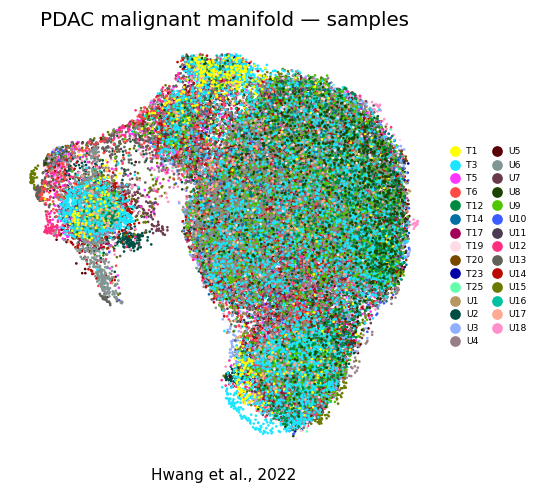

In [ ]:
os.makedirs(pth_fig, exist_ok=True)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=12, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1, .5),
          columnspacing=.5, handletextpad=.25, fontsize=6)
ax.set_title('PDAC malignant manifold — samples', size=13)
ax.text(.5, -.05, 'Hwang et al., 2022', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf')